<a href="https://colab.research.google.com/github/Nivetha-B93/Classification-Algorithms-Model-Building/blob/main/Classification_Algorithms_Model_Building.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Task 1 – Data Exploration & Preprocessing**
# Load and inspect the dataset

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

df = pd.read_csv(
    "https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/refs/heads/main/crowdfunding.csv"
)

# Display first 5 rows
display(df.head())

# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

# Statistical summary
display(df.describe(include="all"))

,Unnamed: 0,CampaignID,GoalAmount,RaisedAmount,DurationDays,NumBackers,Category,LaunchMonth,Country,Currency,OwnerExperience,VideoIncluded,SocialMediaPresence,NumUpdates,IsSuccessful
0,0,CID_00000,76159,73518.028955,15,1903,Film,September,Australia,GBP,11,Yes,41758,3,0
1,1,CID_00001,69394,60068.683288,49,469,Art,October,Australia,GBP,7,Yes,79112,48,0
2,2,CID_00002,18652,22958.153470,58,148,Film,February,USA,EUR,17,No,3942,9,1
3,3,CID_00003,19487,24229.048390,39,780,Film,October,Germany,AUD,10,No,22047,35,1
4,4,CID_00004,26734,17984.630311,68,1622,Games,September,Australia,AUD,12,Yes,72568,17,0


Dataset shape: (100000, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 15 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Unnamed: 0           100000 non-null  int64  
 1   CampaignID           100000 non-null  object 
 2   GoalAmount           100000 non-null  int64  
 3   RaisedAmount         100000 non-null  float64
 4   DurationDays         100000 non-null  int64  
 5   NumBackers           100000 non-null  int64  
 6   Category             100000 non-null  object 
 7   LaunchMonth          100000 non-null  object 
 8   Country              100000 non-null  object 
 9   Currency             100000 non-null  object 
 10  OwnerExperience      100000 non-null  int64  
 11  VideoIncluded        100000 non-null  object 
 12  SocialMediaPresence  100000 non-null  int64  
 13  NumUpdates           100000 non-null  int64  
 14  IsSuccessful         100000 non-null  int

,Unnamed: 0,CampaignID,GoalAmount,RaisedAmount,DurationDays,NumBackers,Category,LaunchMonth,Country,Currency,OwnerExperience,VideoIncluded,SocialMediaPresence,NumUpdates,IsSuccessful
count,100000.000000,100000,100000.000000,100000.000000,100000.000000,100000.000000,100000,100000,100000,100000,100000.000000,100000,100000.000000,100000.000000,100000.000000
unique,NaN,100000,NaN,NaN,NaN,NaN,5,12,5,5,NaN,2,NaN,NaN,NaN
top,NaN,CID_99983,NaN,NaN,NaN,NaN,Art,December,Germany,GBP,NaN,No,NaN,NaN,NaN
freq,NaN,1,NaN,NaN,NaN,NaN,20145,8487,20201,20196,NaN,50182,NaN,NaN,NaN
mean,49999.500000,NaN,50538.001310,50598.121803,52.047370,1003.347340,NaN,NaN,NaN,NaN,9.489130,NaN,50077.301010,24.483230,0.500940
std,28867.657797,NaN,28613.822592,33255.277493,21.653238,574.485153,NaN,NaN,NaN,NaN,5.763538,NaN,28767.521522,14.413833,0.500002
min,0.000000,NaN,1000.000000,528.632349,15.000000,10.000000,NaN,NaN,NaN,NaN,0.000000,NaN,100.000000,0.000000,0.000000
25%,24999.750000,NaN,25724.750000,23396.500017,33.000000,505.000000,NaN,NaN,NaN,NaN,4.000000,NaN,25276.750000,12.000000,0.000000
50%,49999.500000,NaN,50706.000000,45980.674476,52.000000,1003.000000,NaN,NaN,NaN,NaN,9.000000,NaN,50024.500000,25.000000,1.000000
75%,74999.250000,NaN,75316.000000,72790.183158,71.000000,1502.000000,NaN,NaN,NaN,NaN,14.000000,NaN,74934.250000,37.000000,1.000000


## **Handling missing values and duplicates**

In [ ]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Missing values:
Unnamed: 0             0
CampaignID             0
GoalAmount             0
RaisedAmount           0
DurationDays           0
NumBackers             0
Category               0
LaunchMonth            0
Country                0
Currency               0
OwnerExperience        0
VideoIncluded          0
SocialMediaPresence    0
NumUpdates             0
IsSuccessful           0
dtype: int64
Number of duplicate rows: 0


## **Dropping the column**

In [ ]:
df.drop(columns=["Unnamed: 0"], errors="ignore", inplace=True)

## **Encoding categorical variables**

In [ ]:
from sklearn.preprocessing import OneHotEncoder


# Exclude the identifier
categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns.drop('CampaignID', errors='ignore')

# Select categorical data and handle missing values
categorical_data = df[categorical_columns].fillna("Unknown")

# Create the encoder
ohe = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Encode categorical data
encoded_data = ohe.fit_transform(categorical_data)

# Convert encoded data into a DataFrame
encoded_df = pd.DataFrame(
    encoded_data,
    columns=ohe.get_feature_names_out(categorical_columns),
    index=df.index
)

display(encoded_df.head())

print("Encoded dataset shape:", encoded_df.shape)


,Category_Art,Category_Film,Category_Games,Category_Music,Category_Technology,LaunchMonth_April,LaunchMonth_August,LaunchMonth_December,LaunchMonth_February,LaunchMonth_January,...,Country_Germany,Country_UK,Country_USA,Currency_AUD,Currency_CAD,Currency_EUR,Currency_GBP,Currency_USD,VideoIncluded_No,VideoIncluded_Yes
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


Encoded dataset shape: (100000, 29)


In [ ]:
# Identify numerical columns
numerical_columns = df.select_dtypes(
    include='number'
).columns.drop('CampaignID', errors='ignore')

# Combine numerical and encoded categorical columns
df_processed = pd.concat(
    [
        df[numerical_columns],
        encoded_df
    ],
    axis=1
)

print("Processed dataset shape:", df_processed.shape)

display(df_processed.head())

Processed dataset shape: (100000, 37)


,GoalAmount,RaisedAmount,DurationDays,NumBackers,OwnerExperience,SocialMediaPresence,NumUpdates,IsSuccessful,Category_Art,Category_Film,...,Country_Germany,Country_UK,Country_USA,Currency_AUD,Currency_CAD,Currency_EUR,Currency_GBP,Currency_USD,VideoIncluded_No,VideoIncluded_Yes
0,76159,73518.028955,15,1903,11,41758,3,0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
1,69394,60068.683288,49,469,7,79112,48,0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
2,18652,22958.153470,58,148,17,3942,9,1,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,19487,24229.048390,39,780,10,22047,35,1,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,26734,17984.630311,68,1622,12,72568,17,0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


## **Performing feature selection**

In [ ]:
# Separate features and target
X = df_processed.drop(columns=['IsSuccessful'])
y = df_processed['IsSuccessful']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (100000, 36)
Target shape: (100000,)


# **Split the dataset into training and testing sets**

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (80000, 36)
X_test shape: (20000, 36)
y_train shape: (80000,)
y_test shape: (20000,)


# **Selecting best features**

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif

# Select the 10 best features
selector = SelectKBest(
    score_func=f_classif,
    k=10
)

# Fit on training data and select features
X_train_selected = selector.fit_transform(
    X_train,
    y_train
)

# Apply the same selection to test data
X_test_selected = selector.transform(X_test)

# Get selected feature names
selected_features = X.columns[selector.get_support()]

print("Selected features:")
print(selected_features.tolist())

print("\nTraining shape after selection:", X_train_selected.shape)
print("Testing shape after selection:", X_test_selected.shape)

Selected features:
['RaisedAmount', 'OwnerExperience', 'Category_Art', 'Category_Music', 'LaunchMonth_April', 'LaunchMonth_January', 'LaunchMonth_October', 'LaunchMonth_September', 'Country_Germany', 'Country_UK']

Training shape after selection: (80000, 10)
Testing shape after selection: (20000, 10)


In [ ]:
feature_scores = pd.DataFrame({
    'Feature': X.columns,
    'F_Score': selector.scores_,
    'Selected': selector.get_support()
})

feature_scores = feature_scores.sort_values(
    by='F_Score',
    ascending=False
)

display(feature_scores)

,Feature,F_Score,Selected
1,RaisedAmount,13649.160697,True
4,OwnerExperience,6.745279,True
22,LaunchMonth_October,3.929400,True
7,Category_Art,3.560495,True
16,LaunchMonth_January,3.354229,True
27,Country_UK,2.791118,True
23,LaunchMonth_September,1.961601,True
26,Country_Germany,1.813667,True
10,Category_Music,1.810700,True
12,LaunchMonth_April,1.782798,True


## **Applying feature scaling **

In [ ]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit on training data and scale it
X_train_scaled = scaler.fit_transform(X_train_selected)

# Scale test data using the same parameters
X_test_scaled = scaler.transform(X_test_selected)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (80000, 10)
Scaled testing shape: (20000, 10)


In [ ]:
X_train_scaled = scaler.fit_transform(X_train_selected)

In [ ]:
X_test_scaled = scaler.transform(X_test_selected)

## **Task 2 – Classification Model Building**
Build and train the following classification models:
● Random Forest Classifier
● KNN
● Decision Tree
● Naive Bayes Classifier
● Support Vector Machine (SVM)

In [ ]:
# 1. Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_selected, y_train)


# 2. K-Nearest Neighbors
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights="uniform"
)

knn_model.fit(X_train_scaled, y_train)


# 3. Decision Tree
dt_model = DecisionTreeClassifier(
    max_depth=10,
    min_samples_split=10,
    random_state=42
)

dt_model.fit(X_train_selected, y_train)


# 4. Naive Bayes
nb_model = GaussianNB()

nb_model.fit(X_train_selected, y_train)


# 5. Support Vector Machine
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)


print("All five classification models have been trained!")

All five classification models have been trained!


In [ ]:
models = {
    "Random Forest": rf_model,
    "KNN": knn_model,
    "Decision Tree": dt_model,
    "Naive Bayes": nb_model,
    "SVM": svm_model
}

print("Models ready for evaluation:")
print(list(models.keys()))

Models ready for evaluation:
['Random Forest', 'KNN', 'Decision Tree', 'Naive Bayes', 'SVM']


## **TASK 3 — Model Evaluation**
Calculating accuracy, precision, recall, and F1-score
# **Compare training and testing performance.**

In [ ]:
results = []

for name, model in models.items():

    # Select the appropriate features
    if name in ["KNN", "SVM"]:
        X_train_model = X_train_scaled
        X_test_model = X_test_scaled
    else:
        X_train_model = X_train_selected
        X_test_model = X_test_selected

    # Predictions on training data
    y_train_pred = model.predict(X_train_model)

    # Predictions on testing data
    y_test_pred = model.predict(X_test_model)

    # Store the evaluation metrics
    results.append({
        "Model": name,

        "Train Accuracy": accuracy_score(
            y_train, y_train_pred
        ),
        "Test Accuracy": accuracy_score(
            y_test, y_test_pred
        ),

        "Train Precision": precision_score(
            y_train, y_train_pred, zero_division=0
        ),
        "Test Precision": precision_score(
            y_test, y_test_pred, zero_division=0
        ),

        "Train Recall": recall_score(
            y_train, y_train_pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, y_test_pred, zero_division=0
        ),

        "Train F1-Score": f1_score(
            y_train, y_train_pred, zero_division=0
        ),
        "Test F1-Score": f1_score(
            y_test, y_test_pred, zero_division=0
        )
    })

evaluation_df = pd.DataFrame(results)

display(evaluation_df.round(4))

,Model,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1-Score,Test F1-Score
0,Random Forest,0.6822,0.6720,0.8172,0.8017,0.4708,0.4585,0.5974,0.5834
1,KNN,0.7497,0.6168,0.7778,0.6294,0.7005,0.5718,0.7371,0.5992
2,Decision Tree,0.6747,0.6710,0.7968,0.7929,0.4706,0.4646,0.5917,0.5859
3,Naive Bayes,0.6651,0.6704,0.7349,0.7449,0.5184,0.5202,0.6080,0.6126
4,SVM,0.6686,0.6713,0.8275,0.8340,0.4276,0.4293,0.5638,0.5668


The five classification models—Random Forest, K-Nearest Neighbors, Decision Tree, Naive Bayes, and Support Vector Machine—were evaluated using accuracy, precision, recall, and F1-score on both training and testing datasets.

Random Forest achieved the highest test accuracy of 67.20%, while SVM achieved the highest test precision of 83.40%. Naive Bayes achieved the highest test recall of 52.02% and the highest test F1-score of 61.26%, making it the best-performing model according to the F1-score criterion.

The training and testing performance of Random Forest, Decision Tree, Naive Bayes, and SVM was relatively consistent. KNN showed a larger accuracy gap of 13.29 percentage points, indicating possible overfitting.

Although Naive Bayes provided the best balance between precision and recall, its recall of 52.02% indicates that the model failed to identify a considerable proportion of successful campaigns. Further improvements could include feature engineering, hyperparameter optimization, threshold adjustment, and evaluation of class imbalance where appropriate.

Overall, **Naive Bayes was selected as the preferred model** based on its test F1-score. The final selection should also consider the confusion matrix, cross-validation results, and the practical consequences of false positive and false negative predictions.


# **Ploting training versus testing performance**

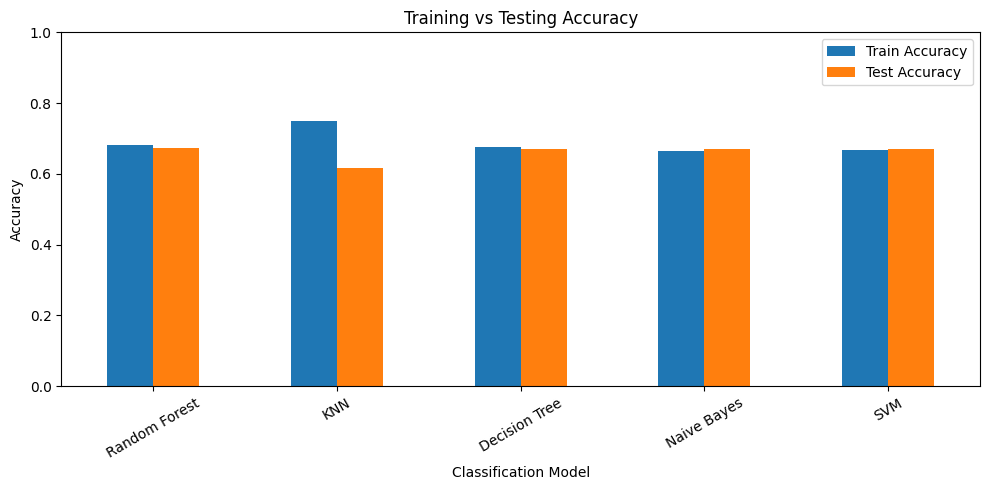

In [ ]:
accuracy_comparison = evaluation_df.set_index("Model")[
    ["Train Accuracy", "Test Accuracy"]
]

accuracy_comparison.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Training vs Testing Accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Classification Model")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

The graph compares the training and testing accuracy of five classification models: Random Forest, K-Nearest Neighbors (KNN), Decision Tree, Naive Bayes, and Support Vector Machine (SVM). Random Forest achieved the highest testing accuracy of 67.20%, followed by Decision Tree at 67.10%, SVM at 67.13%, and Naive Bayes at 67.04%. KNN achieved the highest training accuracy of 74.97%, but its testing accuracy dropped to 61.68%, indicating possible overfitting. Random Forest, Decision Tree, Naive Bayes, and SVM showed relatively small differences between training and testing accuracy, suggesting more consistent generalization to unseen data. Although Random Forest achieved the highest testing accuracy, Naive Bayes produced the highest test F1-score in the earlier evaluation. Therefore, the final model should be selected based on multiple evaluation metrics rather than accuracy alone

# **confusion matrices**

A confusion matrix shows correct and incorrect classifications

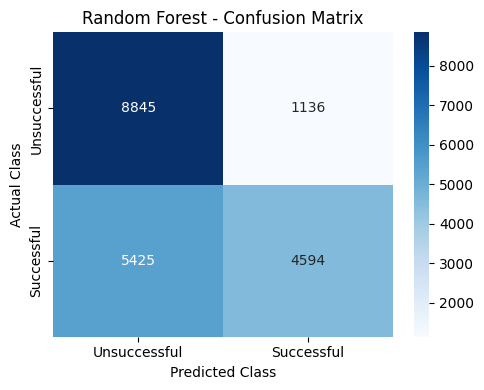


Classification Report: Random Forest
              precision    recall  f1-score   support

Unsuccessful       0.62      0.89      0.73      9981
  Successful       0.80      0.46      0.58     10019

    accuracy                           0.67     20000
   macro avg       0.71      0.67      0.66     20000
weighted avg       0.71      0.67      0.66     20000



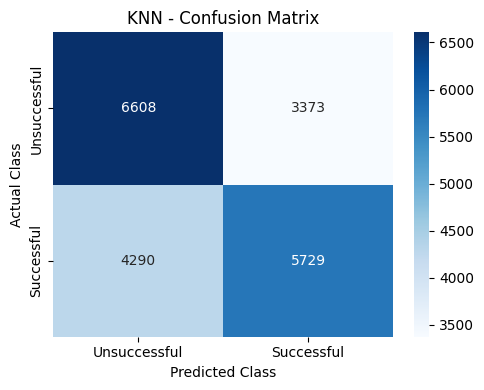


Classification Report: KNN
              precision    recall  f1-score   support

Unsuccessful       0.61      0.66      0.63      9981
  Successful       0.63      0.57      0.60     10019

    accuracy                           0.62     20000
   macro avg       0.62      0.62      0.62     20000
weighted avg       0.62      0.62      0.62     20000



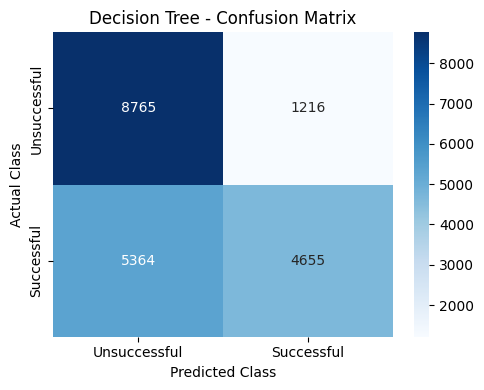


Classification Report: Decision Tree
              precision    recall  f1-score   support

Unsuccessful       0.62      0.88      0.73      9981
  Successful       0.79      0.46      0.59     10019

    accuracy                           0.67     20000
   macro avg       0.71      0.67      0.66     20000
weighted avg       0.71      0.67      0.66     20000



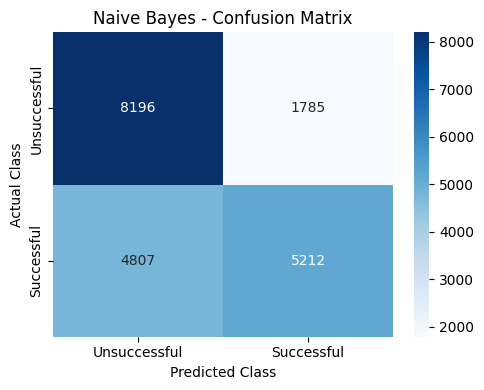


Classification Report: Naive Bayes
              precision    recall  f1-score   support

Unsuccessful       0.63      0.82      0.71      9981
  Successful       0.74      0.52      0.61     10019

    accuracy                           0.67     20000
   macro avg       0.69      0.67      0.66     20000
weighted avg       0.69      0.67      0.66     20000



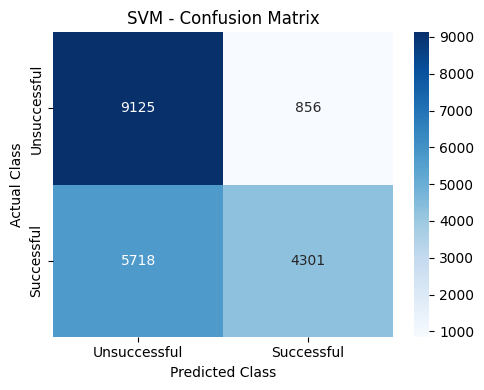


Classification Report: SVM
              precision    recall  f1-score   support

Unsuccessful       0.61      0.91      0.74      9981
  Successful       0.83      0.43      0.57     10019

    accuracy                           0.67     20000
   macro avg       0.72      0.67      0.65     20000
weighted avg       0.72      0.67      0.65     20000



In [ ]:
for name, model in models.items():

    if name in ["KNN", "SVM"]:
        X_test_model = X_test_scaled
    else:
        X_test_model = X_test_selected

    y_test_pred = model.predict(X_test_model)

    cm = confusion_matrix(
        y_test,
        y_test_pred,
        labels=[0, 1]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Unsuccessful", "Successful"],
        yticklabels=["Unsuccessful", "Successful"]
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.show()

    print(f"\nClassification Report: {name}")

    print(
        classification_report(
            y_test,
            y_test_pred,
            labels=[0, 1],
            target_names=["Unsuccessful", "Successful"],
            zero_division=0
        )
    )

## Task 4 – Cross-Validation & Hyperparameter Tuning
● Apply Cross-Validation to evaluate model stability
● Perform Hyperparameter Tuning using GridSearchCV or RandomizedSearchCV
● Identify the best parameters for each model

## **Cross-Validation and Hyperparameter Tuning**

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    if name in ["KNN", "SVM"]:
        X_cv = X_train_scaled
    else:
        X_cv = X_train_selected

    scores = cross_val_score(
        model,
        X_cv,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "Fold 1 F1": scores[0],
        "Fold 2 F1": scores[1],
        "Fold 3 F1": scores[2],
        "Mean CV F1": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.sort_values(
        by="Mean CV F1",
        ascending=False
    ).round(4)
)

,Model,Fold 1 F1,Fold 2 F1,Fold 3 F1,Mean CV F1,Standard Deviation
3,Naive Bayes,0.6075,0.6108,0.6054,0.6079,0.0023
1,KNN,0.5987,0.5982,0.6007,0.5992,0.0011
0,Random Forest,0.5780,0.5813,0.5707,0.5767,0.0044
2,Decision Tree,0.5775,0.5770,0.5739,0.5761,0.0016
4,SVM,0.5655,0.5653,0.5600,0.5636,0.0026


In [ ]:
from sklearn.model_selection import GridSearchCV

rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20],
    "min_samples_split": [2, 10]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ),
    param_grid=rf_param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train_selected, y_train)

print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print("Best cross-validation F1-score:")
print(round(rf_grid.best_score_, 4))

best_rf = rf_grid.best_estimator_

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Random Forest parameters:
{'max_depth': 20, 'min_samples_split': 10, 'n_estimators': 100}
Best cross-validation F1-score:
0.5918


In [ ]:
dt_param_grid = {
    "max_depth": [5, 10, 20],
    "min_samples_split": [2, 10],
    "min_samples_leaf": [1, 2],
    "criterion": ["gini", "entropy"]
}

dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt_param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

dt_grid.fit(X_train_selected, y_train)

print("Best Decision Tree parameters:")
print(dt_grid.best_params_)

print("Best cross-validation F1-score:")
print(round(dt_grid.best_score_, 4))

best_dt = dt_grid.best_estimator_

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best Decision Tree parameters:
{'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best cross-validation F1-score:
0.5847


In [ ]:
knn_param_grid = {
    "n_neighbors": [3, 5, 7],
    "weights": ["uniform", "distance"],
    "p": [1, 2]
}

knn_grid = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=knn_param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

knn_grid.fit(X_train_scaled, y_train)

print("Best KNN parameters:")
print(knn_grid.best_params_)

print("Best cross-validation F1-score:")
print(round(knn_grid.best_score_, 4))

best_knn = knn_grid.best_estimator_

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best KNN parameters:
{'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
Best cross-validation F1-score:
0.5986


In [ ]:
nb_param_grid = {
    "var_smoothing": [1e-9, 1e-8, 1e-7, 1e-6]
}

nb_grid = GridSearchCV(
    estimator=GaussianNB(),
    param_grid=nb_param_grid,
    scoring="f1",
    cv=3,
    n_jobs=1,
    verbose=1
)

nb_grid.fit(X_train_selected, y_train)

print("Best Naive Bayes parameters:")
print(nb_grid.best_params_)

print("Best cross-validation F1-score:")
print(round(nb_grid.best_score_, 4))

best_nb = nb_grid.best_estimator_

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Naive Bayes parameters:
{'var_smoothing': 1e-08}
Best cross-validation F1-score:
0.608


In [ ]:
from sklearn.model_selection import train_test_split

X_svm_sample, _, y_svm_sample, _ = train_test_split(
    X_train_scaled,
    y_train,
    train_size=10000,
    random_state=42,
    stratify=y_train
)

svm_param_grid = {
    "C": [0.1, 1, 10],
    "kernel": ["rbf"]
}

svm_grid = GridSearchCV(
    estimator=SVC(),
    param_grid=svm_param_grid,
    scoring="f1",
    cv=3,
    n_jobs=1,
    verbose=1
)

svm_grid.fit(X_svm_sample, y_svm_sample)

print("Best SVM parameters from the sample:")
print(svm_grid.best_params_)

print("Best sample cross-validation F1-score:")
print(round(svm_grid.best_score_, 4))

best_svm = svm_grid.best_estimator_

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best SVM parameters from the sample:
{'C': 0.1, 'kernel': 'rbf'}
Best sample cross-validation F1-score:
0.5701


In [ ]:
best_models = {
    "Random Forest": best_rf,
    "KNN": best_knn,
    "Decision Tree": best_dt,
    "Naive Bayes": best_nb,
    "SVM": best_svm
}

tuning_results = pd.DataFrame([
    {
        "Model": name,
        "Best Parameters": str(model.get_params(deep=False))
    }
    for name, model in best_models.items()
])

display(tuning_results)

,Model,Best Parameters
0,Random Forest,"{'bootstrap': True, 'ccp_alpha': 0.0, 'class_w..."
1,KNN,"{'algorithm': 'auto', 'leaf_size': 30, 'metric..."
2,Decision Tree,"{'ccp_alpha': 0.0, 'class_weight': None, 'crit..."
3,Naive Bayes,"{'priors': None, 'var_smoothing': 1e-08}"
4,SVM,"{'C': 0.1, 'break_ties': False, 'cache_size': ..."


## **Model Comparison and Selection**

In [ ]:
tuned_results = []

for name, model in best_models.items():

    if name in ["KNN", "SVM"]:
        X_train_model = X_train_scaled
        X_test_model = X_test_scaled
    else:
        X_train_model = X_train_selected
        X_test_model = X_test_selected

    # Predict training data
    y_train_pred = model.predict(X_train_model)

    # Predict testing data
    y_test_pred = model.predict(X_test_model)

    tuned_results.append({
        "Model": name,

        "Train Accuracy": accuracy_score(
            y_train, y_train_pred
        ),

        "Test Accuracy": accuracy_score(
            y_test, y_test_pred
        ),

        "Test Precision": precision_score(
            y_test, y_test_pred, zero_division=0
        ),

        "Test Recall": recall_score(
            y_test, y_test_pred, zero_division=0
        ),

        "Test F1-Score": f1_score(
            y_test, y_test_pred, zero_division=0
        )
    })

final_results_df = pd.DataFrame(tuned_results)

final_results_df["Accuracy Gap"] = (
    final_results_df["Train Accuracy"]
    - final_results_df["Test Accuracy"]
)

display(
    final_results_df.sort_values(
        by="Test F1-Score",
        ascending=False
    ).round(4)
)

,Model,Train Accuracy,Test Accuracy,Test Precision,Test Recall,Test F1-Score,Accuracy Gap
3,Naive Bayes,0.6650,0.6702,0.7446,0.5201,0.6124,-0.0053
1,KNN,0.7973,0.6105,0.6184,0.5811,0.5992,0.1868
0,Random Forest,0.7768,0.6514,0.7157,0.5047,0.5920,0.1254
2,Decision Tree,0.6702,0.6730,0.8000,0.4630,0.5865,-0.0028
4,SVM,0.6675,0.6722,0.8067,0.4544,0.5814,-0.0046


There is an important distinction between task 3 and task 5:

Task 3: Evaluated the baseline models before systematic hyperparameter tuning.
Task 5: Compared the tuned models and select the most suitable model.

This way, you can also see whether tuning improved performance

## **Plotting the final comparison**

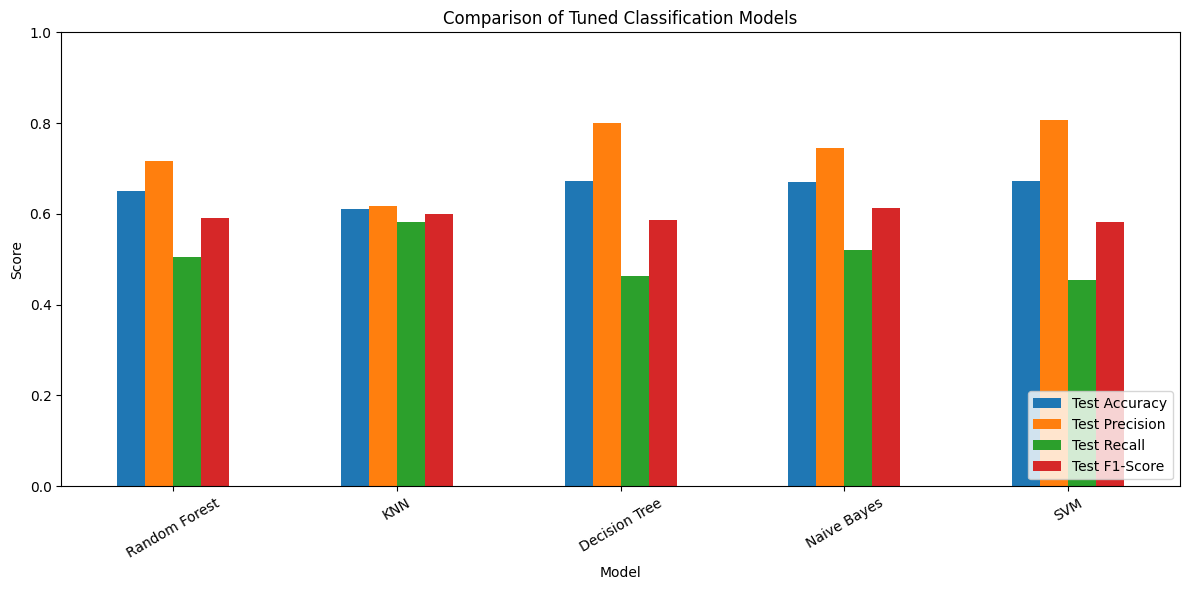

In [ ]:
final_comparison = final_results_df.set_index("Model")[
    ["Test Accuracy", "Test Precision", "Test Recall", "Test F1-Score"]
]

final_comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Tuned Classification Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# **Identifying the best-performing model**

In [ ]:
best_result = final_results_df.sort_values(
    by="Test F1-Score",
    ascending=False
).iloc[0]

print("Best-performing model:", best_result["Model"])
print("Test Accuracy:", round(best_result["Test Accuracy"], 4))
print("Test Precision:", round(best_result["Test Precision"], 4))
print("Test Recall:", round(best_result["Test Recall"], 4))
print("Test F1-Score:", round(best_result["Test F1-Score"], 4))
print("Accuracy Gap:", round(best_result["Accuracy Gap"], 4))

Best-performing model: Naive Bayes
Test Accuracy: 0.6702
Test Precision: 0.7446
Test Recall: 0.5201
Test F1-Score: 0.6124
Accuracy Gap: -0.0053


## **Discuss strengths, weaknesses, and possible improvements**
**Final Conclusion**
The evaluation shows that each classification model has different strengths. Decision Tree achieved the highest test accuracy of 67.30%, SVM achieved the highest precision of 80.67%, and KNN achieved the highest recall of 58.11%. However, KNN showed a substantial training–testing accuracy gap, suggesting possible overfitting.

Naive Bayes was selected as the preferred model because it achieved the highest test F1-score of 61.24%, providing the best balance between precision and recall among the five models. Nevertheless, its recall of 52.01% indicates that further improvement is needed to identify more successful campaigns. Hyperparameter tuning, cross-validation, feature engineering, and classification threshold adjustment may improve performance.

The final model should be confirmed using the hyperparameter-tuning and cross-validation results, with particular attention to preventing data leakage and achieving reliable predictions on unseen campaigns